# Malaria Cell Classification: Custom CNN vs MobileNetV2

This notebook compares two Deep Learning architectures on the **TFDS Malaria** dataset (27,558 thin blood smear cell images, binary classification: `Parasitized` vs `Uninfected`):
1. **Custom CNN (Baseline):** 3-block `Conv2D` + `BatchNormalization` + `MaxPooling2D` (`32 -> 64 -> 128`) with `GlobalAveragePooling2D`, `Dropout(0.4)`, and `Dense(128)`.
2. **MobileNetV2 (Transfer Learning):** ImageNet-pretrained `MobileNetV2` with Phase 1 (frozen feature extraction) and Phase 2 (fine-tuning top 30 layers at `lr=1e-5`).

In [3]:
import os
import sys
import subprocess
import random
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

# Auto-clone repository when opened directly in Google Colab
if "google.colab" in sys.modules and not os.path.exists("src"):
    repo_dir = "Malaria-Cell-Classification"
    if not os.path.exists(repo_dir):
        subprocess.run(["git", "clone", "https://github.com/twelverakki/Malaria-Cell-Classification.git"], check=True)
    os.chdir(repo_dir)

# Ensure project root is on sys.path (works from notebooks/ or repo root / Colab)
PROJECT_ROOT = os.path.abspath(os.path.join(os.getcwd(), "..")) if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

OUTPUT_DIR = os.path.join(PROJECT_ROOT, "outputs")
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow version:", tf.__version__)
print("GPUs available:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.21.0
GPUs available: []


## 1. Dataset Loading & Preprocessing (`tf.data`)

In [7]:
!pip install -q importlib_resources

from src.data import load_malaria_datasets

IMG_SIZE = (128, 128)
BATCH_SIZE = 32

train_ds, val_ds, test_ds, class_names, split_counts = load_malaria_datasets(
    img_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    seed=SEED,
)

print("Label mapping:", {idx: name for idx, name in enumerate(class_names)})
print("Split counts:", split_counts)

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/1 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/malaria/incomplete.HBRPOI_1.0.0/malaria-train.tfrecord-[0-9][0-9][0-9][0-9…

Dataset malaria downloaded and prepared to /root/tensorflow_datasets/malaria/1.0.0. Subsequent calls will reuse this data.
Label mapping: {0: 'parasitized', 1: 'uninfected'}
Split counts: {'total': 27558, 'train': 19290, 'val': 4133, 'test': 4135}


In [ ]:
# Preview sample training images
sample_images, sample_labels = next(iter(train_ds))
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for idx, ax in enumerate(axes.ravel()):
    ax.imshow(np.clip(sample_images[idx].numpy(), 0, 255).astype(np.uint8))
    ax.set_title(class_names[int(sample_labels[idx])])
    ax.axis("off")
plt.suptitle("Sample Augmented Training Images", fontsize=13)
plt.tight_layout()
plt.show()

## 2. Model 1: Custom CNN (Baseline)

In [8]:
from src.models import build_custom_cnn, get_callbacks

cnn_model = build_custom_cnn(input_shape=(128, 128, 3), dropout_rate=0.4, learning_rate=1e-3)
cnn_model.summary()

cnn_history = cnn_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=get_callbacks(patience=3),
)

Model: "Custom_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image_input (InputLayer)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescale_0_1 (Rescaling)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_1 (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn_1 (BatchNormalization)       │ (None, 128, 128, 32)   │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_1 (MaxPooling2D)           │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_2 (Conv2D)                 │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn_2 (BatchNormalization)       │ (None, 64, 64, 64)     │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_2 (MaxPooling2D)           │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_3 (Conv2D)                 │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn_3 (BatchNormalization)       │ (None, 32, 32, 128)    │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_3 (MaxPooling2D)           │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_128 (Dense)               │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,785 (432.75 KB)

 Trainable params: 110,337 (431.00 KB)

 Non-trainable params: 448 (1.75 KB)

Epoch 1/15
603/603 ━━━━━━━━━━━━━━━━━━━━ 1206s 2s/step - accuracy: 0.8779 - auc: 0.9411 - loss: 0.3058 - val_accuracy: 0.8602 - val_auc: 0.9431 - val_loss: 0.3446 - learning_rate: 0.0010
Epoch 2/15
603/603 ━━━━━━━━━━━━━━━━━━━━ 1178s 2s/step - accuracy: 0.9397 - auc: 0.9748 - loss: 0.1840 - val_accuracy: 0.9054 - val_auc: 0.9788 - val_loss: 0.2506 - learning_rate: 0.0010
Epoch 3/15
603/603 ━━━━━━━━━━━━━━━━━━━━ 1145s 2s/step - accuracy: 0.9450 - auc: 0.9793 - loss: 0.1664 - val_accuracy: 0.9506 - val_auc: 0.9848 - val_loss: 0.1512 - learning_rate: 0.0010
Epoch 4/15
603/603 ━━━━━━━━━━━━━━━━━━━━ 1154s 2s/step - accuracy: 0.9492 - auc: 0.9824 - loss: 0.1539 - val_accuracy: 0.9320 - val_auc: 0.9771 - val_loss: 0.2540 - learning_rate: 0.0010
Epoch 5/15
603/603 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9504 - auc: 0.9834 - loss: 0.1495
Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
603/603 ━━━━━━━━━━━━━━━━━━━━ 1138s 2s/step - accuracy: 0.9510 - auc: 0.9846 - los

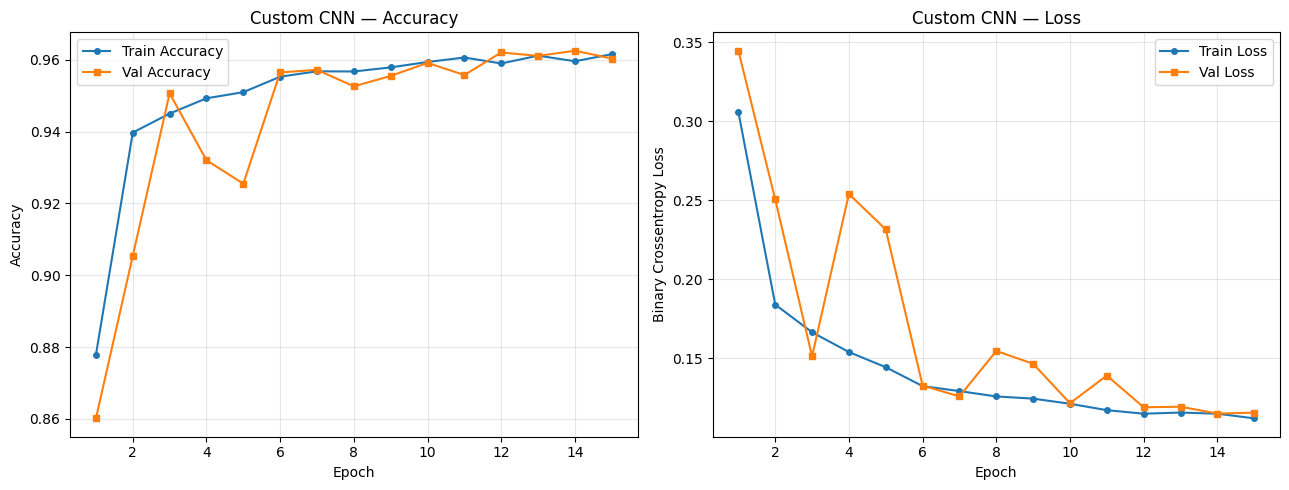

Custom CNN Test Metrics: {'Model': 'Custom CNN', 'Accuracy': 0.9644498186215236, 'Precision': 0.9506641366223909, 'Recall': 0.9789936492427943, 'F1-Score': 0.9646209386281589, 'ROC-AUC': 0.9910519927302267}


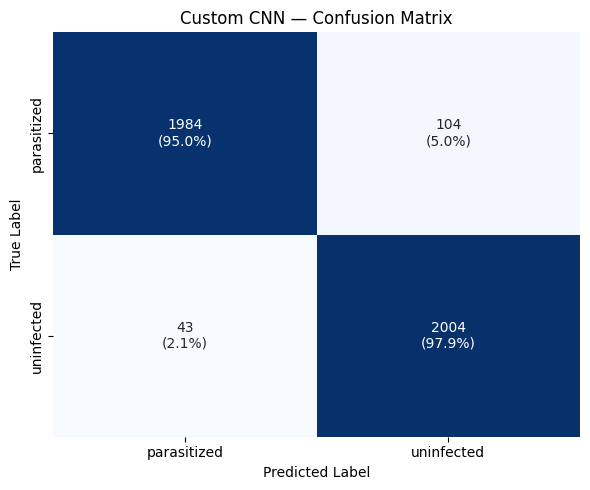

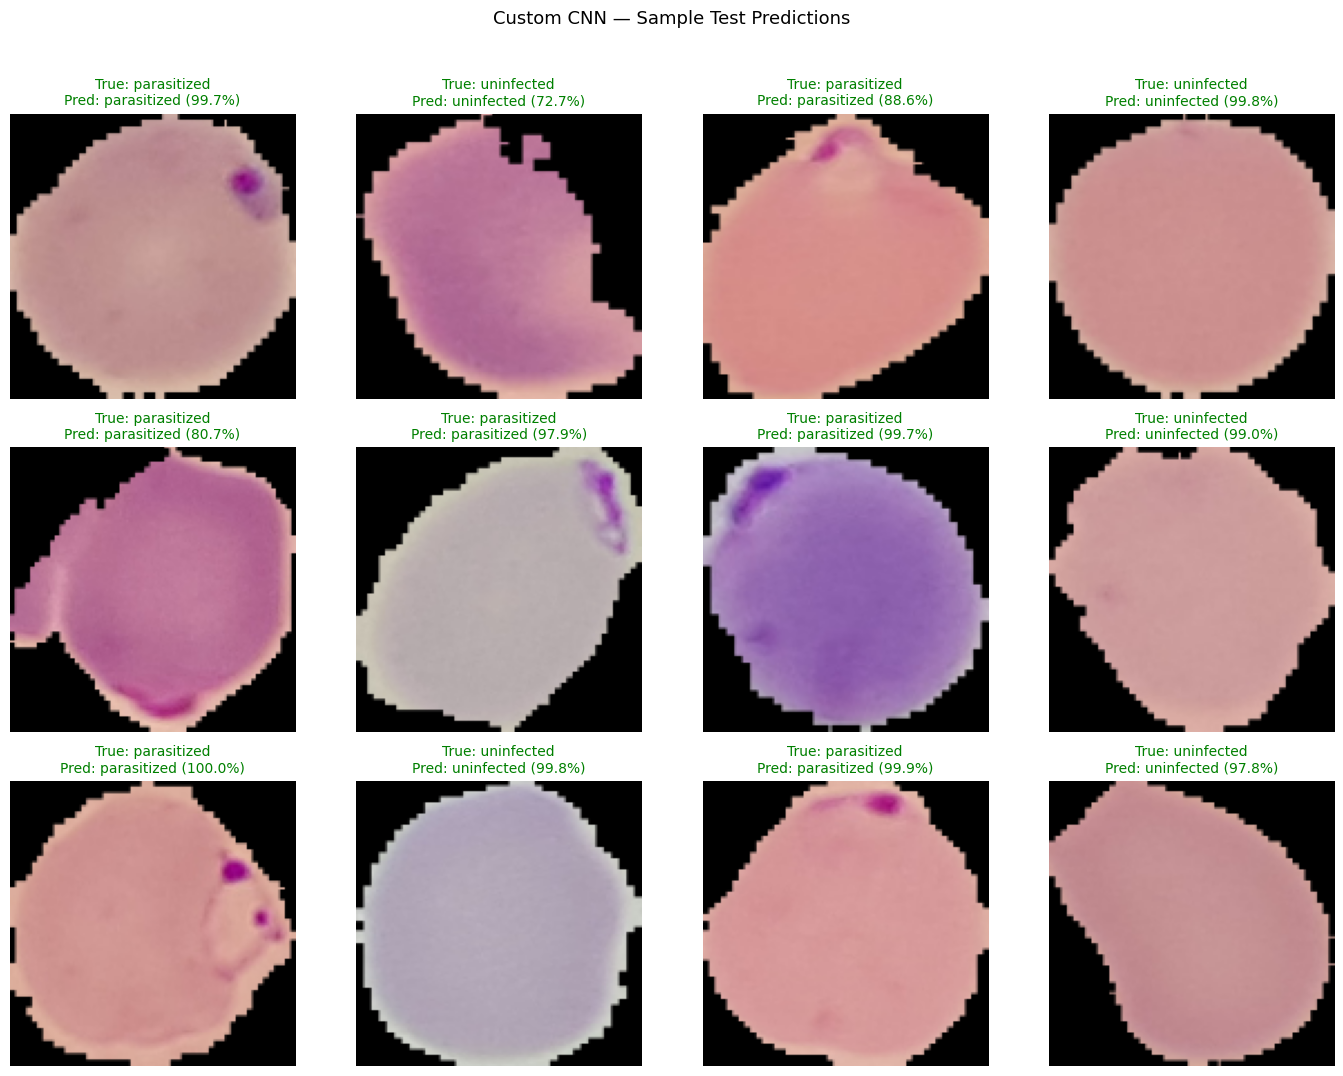

In [9]:
from src.evaluate import (
    evaluate_model,
    plot_training_history,
    plot_confusion_matrix,
    plot_sample_predictions,
)

plot_training_history(
    cnn_history.history,
    model_name="Custom CNN",
    save_path=os.path.join(OUTPUT_DIR, "custom_cnn_history.png"),
)

cnn_results = evaluate_model(cnn_model, test_ds, model_name="Custom CNN")
print("Custom CNN Test Metrics:", cnn_results["metrics"])

plot_confusion_matrix(
    cnn_results["y_true"],
    cnn_results["y_pred"],
    class_names=class_names,
    model_name="Custom CNN",
    save_path=os.path.join(OUTPUT_DIR, "custom_cnn_cm.png"),
)

plot_sample_predictions(
    cnn_model,
    test_ds,
    class_names=class_names,
    model_name="Custom CNN",
    save_path=os.path.join(OUTPUT_DIR, "custom_cnn_samples.png"),
)

## 3. Model 2: Transfer Learning (`MobileNetV2`)

- **Phase 1:** Feature extraction with frozen ImageNet backbone (10 epochs, `lr=1e-3`).
- **Phase 2:** Fine-tuning top 30 layers (up to 10 epochs, `lr=1e-5`).

In [ ]:
from src.models import build_mobilenetv2, unfreeze_for_finetuning

mobilenet_model, base_model = build_mobilenetv2(
    input_shape=(128, 128, 3),
    dropout_rate=0.3,
    learning_rate=1e-3,
)
mobilenet_model.summary()

# Phase 1: Feature Extraction
mn_hist_phase1 = mobilenet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=get_callbacks(patience=3),
)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "MobileNetV2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image_input (InputLayer)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_preprocess          │ (None, 128, 128, 3)    │             0 │
│ (Rescaling)                     │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_128            │ (None, 4, 4, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Epoch 1/10


In [ ]:
# Phase 2: Fine-Tuning top 30 layers
mobilenet_model = unfreeze_for_finetuning(
    mobilenet_model,
    base_model,
    unfreeze_top_n=30,
    learning_rate=1e-5,
)

mn_hist_phase2 = mobilenet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=get_callbacks(patience=3),
)

In [ ]:
from src.evaluate import merge_histories

mn_merged_hist, split_epoch = merge_histories(mn_hist_phase1, mn_hist_phase2)

plot_training_history(
    mn_merged_hist,
    model_name="MobileNetV2 (Transfer Learning + Fine-Tuning)",
    save_path=os.path.join(OUTPUT_DIR, "mobilenetv2_history.png"),
    fine_tune_epoch=split_epoch,
)

mn_results = evaluate_model(mobilenet_model, test_ds, model_name="MobileNetV2")
print("MobileNetV2 Test Metrics:", mn_results["metrics"])

plot_confusion_matrix(
    mn_results["y_true"],
    mn_results["y_pred"],
    class_names=class_names,
    model_name="MobileNetV2",
    save_path=os.path.join(OUTPUT_DIR, "mobilenetv2_cm.png"),
)

plot_sample_predictions(
    mobilenet_model,
    test_ds,
    class_names=class_names,
    model_name="MobileNetV2",
    save_path=os.path.join(OUTPUT_DIR, "mobilenetv2_samples.png"),
)

## 4. Side-by-Side Model Comparison

In [ ]:
from src.evaluate import build_comparison_table

comparison_df = build_comparison_table([cnn_results, mn_results], save_dir=OUTPUT_DIR)
display(comparison_df.round(4))